: وارد کردن داده‌های آموزش

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


X = np.array([
    [55, 165],
    [65, 170],
    [72, 175],
    [78, 180],
    [80, 160],
    [87, 164],
    [95, 172],
    [100, 185],
    [80, 175],
    [70, 180]
], dtype=float)

y = np.array([1, 1, 1, 1, -1, -1, -1, -1, 1, -1])

train_df = pd.DataFrame({
    "شماره": np.arange(1, 11),
    "وزن (kg)": X[:, 0].astype(int),
    "قد (cm)": X[:, 1].astype(int),
    "برچسب واقعی": y,
    "گروه": ["متناسب (+1)" if label == 1 else "نامتناسب (-1)" for label in y]
})
train_df

,شماره,وزن (kg),قد (cm),برچسب واقعی,گروه
0,1,55,165,1,متناسب (+1)
1,2,65,170,1,متناسب (+1)
2,3,72,175,1,متناسب (+1)
3,4,78,180,1,متناسب (+1)
4,5,80,160,-1,نامتناسب (-1)
5,6,87,164,-1,نامتناسب (-1)
6,7,95,172,-1,نامتناسب (-1)
7,8,100,185,-1,نامتناسب (-1)
8,9,80,175,1,متناسب (+1)
9,10,70,180,-1,نامتناسب (-1)


رسم اولیه:
نمونه‌های متناسب را سبز و نمونه‌های نامتناسب را زرد رسم می‌کنیم.

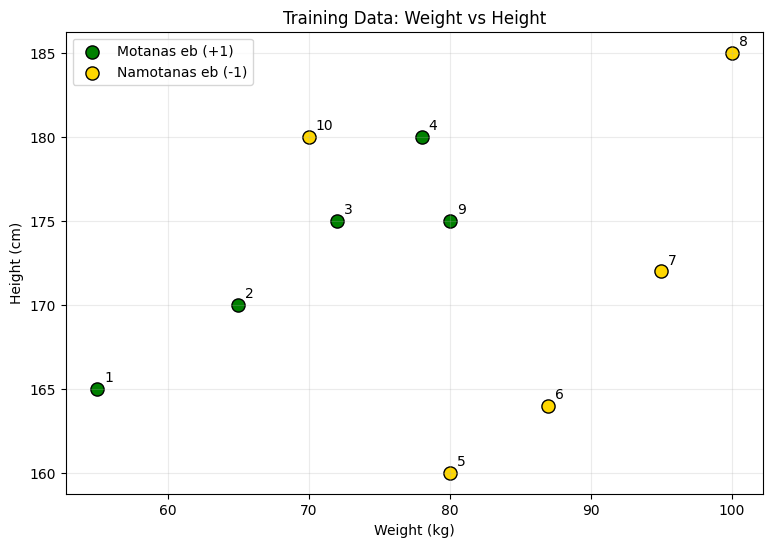

In [2]:
plt.figure(figsize=(9, 6))
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="green", s=90, label="Motanas eb (+1)", edgecolors="black")
plt.scatter(X[y == -1, 0], X[y == -1, 1], color="gold", s=90, label="Namotanas eb (-1)", edgecolors="black")

for i, (weight, height) in enumerate(X, start=1):
    plt.annotate(str(i), (weight, height), xytext=(5, 5), textcoords="offset points")

plt.title("Training Data: Weight vs Height")
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

پاسخ: نه، نمی‌توان همه نمونه‌های دو گروه را با یک خط مستقیم کاملاً جدا کرد. برای نمونه، در وزن ۸۰ کیلوگرم هم نمونه متناسب با قد ۱۷۵ و هم نمونه نامتناسب با قد ۱۶۰ داریم؛ از طرف دیگر، نمونه نامتناسب شماره ۱۰ (وزن ۷۰، قد ۱۸۰) نزدیک ناحیه نمونه‌های متناسب قرار می‌گیرد. بنابراین داده‌ها کاملاً خطی‌جدایی‌پذیر نیستند.

تعریف تابع تصمیم :

تابع تصمیم برابر است با: $g(x)=w_0+w_1x_1+w_2x_2$. اگر مقدار آن بزرگ‌تر یا مساوی صفر باشد، خروجی `+1` و در غیر این صورت `-1` است.

g برای نمونه اول: 215.0
پیش‌بینی نمونه اول: 1


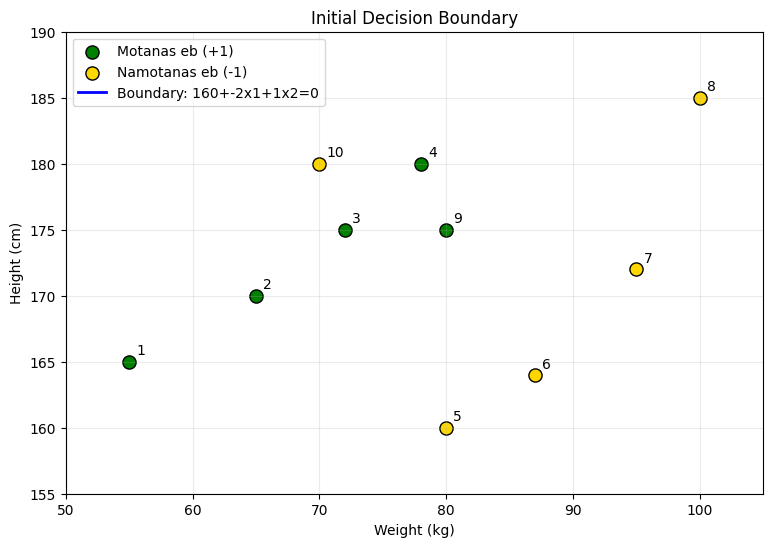

In [ ]:
def decision_function(X, w0, w1, w2):
    return w0 + w1 * X[:, 0] + w2 * X[:, 1]

def predict(X, w0, w1, w2):
    return np.where(decision_function(X, w0, w1, w2) >= 0, 1, -1)

def error_count(X, y, w0, w1, w2):
    y_pred = predict(X, w0, w1, w2)
    return int(np.sum(y_pred != y))

def plot_boundary(X, y, w0, w1, w2, title="Decision Boundary"):
    plt.figure(figsize=(9, 6))
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="green", s=90, label="Motanas eb (+1)", edgecolors="black")
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color="gold", s=90, label="Namotanas eb (-1)", edgecolors="black")
    for i, (weight, height) in enumerate(X, start=1):
        plt.annotate(str(i), (weight, height), xytext=(5, 5), textcoords="offset points")

    # مرز: w0 + w1*x1 + w2*x2 = 0
    x1 = np.linspace(50, 105, 300)
    if w2 != 0:
        x2 = -(w0 + w1 * x1) / w2
        plt.plot(x1, x2, color="blue", linewidth=2, label=f"Boundary: {w0}+{w1}x1+{w2}x2=0")
    elif w1 != 0:
        x_vertical = -w0 / w1
        plt.axvline(x_vertical, color="blue", linewidth=2, label="Decision boundary")
    else:
        print("این وزن‌ها مرز تصمیم قابل رسم ایجاد نمی‌کنند.")

    plt.xlim(50, 105)
    plt.ylim(155, 190)
    plt.title(title)
    plt.xlabel("Weight (kg)")
    plt.ylabel("Height (cm)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


w0, w1, w2 = 160, -2, 1
print("g برای نمونه اول:", decision_function(X[:1], w0, w1, w2)[0])
print("پیش‌بینی نمونه اول:", predict(X[:1], w0, w1, w2)[0])
plot_boundary(X, y, w0, w1, w2, "Initial Decision Boundary")

: محاسبه خطای آموزش

خطا برابر تعداد نمونه‌هایی است که برچسب پیش‌بینی‌شده‌شان با برچسب واقعی فرق دارد. نرخ خطا هم تعداد خطا تقسیم بر ۱۰ است.

In [4]:
def show_training_results(X, y, w0, w1, w2):
    y_pred = predict(X, w0, w1, w2)
    result = pd.DataFrame({
        "شماره": np.arange(1, len(y) + 1),
        "برچسب واقعی": y,
        "برچسب پیش‌بینی": y_pred,
        "نتیجه": np.where(y_pred == y, "درست", "اشتباه")
    })
    errors = int(np.sum(y_pred != y))
    print(result.to_string(index=False))
    print(f"تعداد خطا: {errors}")
    print(f"نرخ خطا: {errors / len(y):.2f} ({100 * errors / len(y):.0f}%)")
    print("شماره نمونه‌های اشتباه:", (np.where(y_pred != y)[0] + 1).tolist())
    return errors

show_training_results(X, y, w0, w1, w2)

 شماره  برچسب واقعی  برچسب پیش‌بینی  نتیجه
     1            1               1   درست
     2            1               1   درست
     3            1               1   درست
     4            1               1   درست
     5           -1               1 اشتباه
     6           -1               1 اشتباه
     7           -1               1 اشتباه
     8           -1               1 اشتباه
     9            1               1   درست
    10           -1               1 اشتباه
تعداد خطا: 5
نرخ خطا: 0.50 (50%)
شماره نمونه‌های اشتباه: [5, 6, 7, 8, 10]


5

:. حداقل پنج آزمایش با وزن‌های متفاوت

In [5]:
experiments = [
    (160, -2, 1),
    (150, -1.8, 1),
    (140, -1.5, 1),
    (130, -1.2, 1),
    (120, -1, 1),
    (100, -0.8, 1)
]

rows = []
for i, (a, b, c) in enumerate(experiments, start=1):
    rows.append({
        "آزمایش": i, "w0": a, "w1": b, "w2": c,
        "خطای آموزش": error_count(X, y, a, b, c)
    })

experiment_df = pd.DataFrame(rows)
experiment_df

,آزمایش,w0,w1,w2,خطای آموزش
0,1,160,-2.0,1,5
1,2,150,-1.8,1,5
2,3,140,-1.5,1,5
3,4,130,-1.2,1,5
4,5,120,-1.0,1,5
5,6,100,-0.8,1,5


: جست‌وجوی ساده برای پیدا کردن وزن‌های بهتر

به‌جای الگوریتم آماده، یک Grid Search ساده می‌نویسیم: چند مقدار برای هر وزن را بررسی می‌کنیم و مجموعه‌ای را نگه می‌داریم که کمترین خطا را دارد. محدوده و گام جست‌وجو در کد مشخص است.

بهترین وزن‌های پیدا شده: {'error': 1, 'w0': -190, 'w1': -2, 'w2': 2}
نرخ خطای آموزش: 0.1


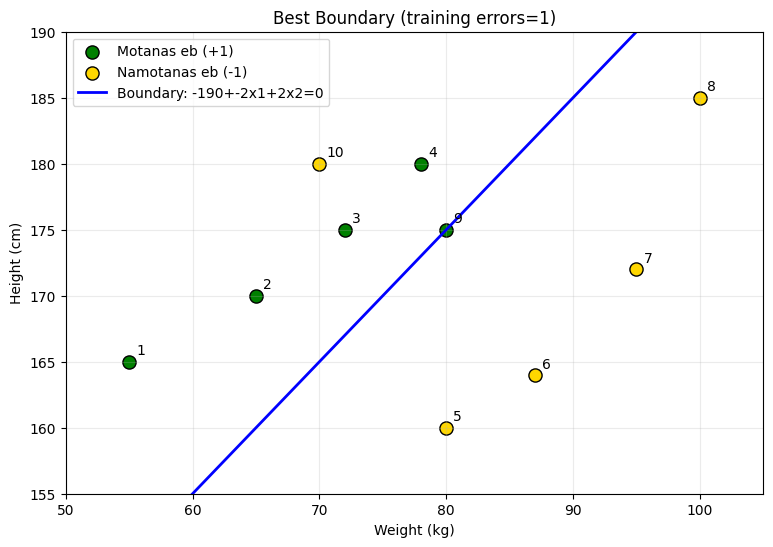

 شماره  برچسب واقعی  برچسب پیش‌بینی  نتیجه
     1            1               1   درست
     2            1               1   درست
     3            1               1   درست
     4            1               1   درست
     5           -1              -1   درست
     6           -1              -1   درست
     7           -1              -1   درست
     8           -1              -1   درست
     9            1               1   درست
    10           -1               1 اشتباه
تعداد خطا: 1
نرخ خطا: 0.10 (10%)
شماره نمونه‌های اشتباه: [10]


1

In [6]:
best = {"error": len(y) + 1, "w0": None, "w1": None, "w2": None}

# محدوده و گام جست‌وجو
for a in range(-200, 201, 10):      # w0
    for b in range(-3, 4, 1):       # w1
        for c in range(-2, 3, 1):   # w2
            if b == 0 and c == 0:
                continue
            e = error_count(X, y, a, b, c)
            if e < best["error"]:
                best = {"error": e, "w0": a, "w1": b, "w2": c}

print("بهترین وزن‌های پیدا شده:", best)
print("نرخ خطای آموزش:", best["error"] / len(y))
plot_boundary(X, y, best["w0"], best["w1"], best["w2"],
              f"Best Boundary (training errors={best['error']})")
show_training_results(X, y, best["w0"], best["w1"], best["w2"])

**چرا خطا به صفر نمی‌رسد؟** طبق خود صورت تمرین، داده‌ها عمداً طوری انتخاب شده‌اند که کاملاً با یک خط جدا نشوند. پس هر خط مستقیم ناچار است دست‌کم یک نمونه را در سمت اشتباه قرار دهد. کم کردن خطا تا حد ممکن مفید است، اما صفر شدن آن با این مدل و این داده‌ها تضمین‌شده نیست.

: آزمون با چهار نمونه جدید

In [7]:
X_test = np.array([
    [60, 168],
    [88, 170],
    [72, 182],
    [92, 180]
], dtype=float)
y_test = np.array([1, -1, 1, -1])

test_pred = predict(X_test, best["w0"], best["w1"], best["w2"])
test_result = pd.DataFrame({
    "شماره": [11, 12, 13, 14],
    "وزن (kg)": X_test[:, 0].astype(int),
    "قد (cm)": X_test[:, 1].astype(int),
    "برچسب واقعی": y_test,
    "برچسب پیش‌بینی": test_pred,
    "نتیجه": np.where(test_pred == y_test, "درست", "اشتباه")
})
test_result, int(np.sum(test_pred != y_test)), float(np.mean(test_pred != y_test))

(   شماره  وزن (kg)  قد (cm)  برچسب واقعی  برچسب پیش‌بینی نتیجه
 0     11        60      168            1               1  درست
 1     12        88      170           -1              -1  درست
 2     13        72      182            1               1  درست
 3     14        92      180           -1              -1  درست,
 0,
 0.0)

: مقایسه خطای آموزش و آزمون

In [8]:
train_errors = error_count(X, y, best["w0"], best["w1"], best["w2"])
test_errors = int(np.sum(test_pred != y_test))

print(f"Training Error: {train_errors}/10 = {train_errors/10:.2f}")
print(f"Test Error: {test_errors}/4 = {test_errors/4:.2f}")

Training Error: 1/10 = 0.10
Test Error: 0/4 = 0.00


**تحلیل:** بهترین وزن‌ها بر اساس داده‌های آموزش انتخاب شده‌اند، بنابراین انتظار داریم عملکردشان روی آموزش خوب باشد؛ ولی لزوماً روی داده‌های جدید بهتر نیستند. کمینه کردن خطای آموزش به‌تنهایی تضمین نمی‌کند خطای آزمون هم کمینه شود. اگر وزن‌ها را بیش از حد بر اساس نمونه‌های آموزش تنظیم کنیم، ممکن است مدل به همان داده‌ها وابسته شود و روی نمونه‌های جدید ضعیف‌تر عمل کند.

: اثر هر وزن روی مرز تصمیم

از رابطه $x_2=-(w_0+w_1x_1)/w_2$، شیب خط برابر $-w_1/w_2$ و عرض از مبدأ آن برابر $-w_0/w_2$ است (به شرط اینکه $w_2\ne0$).

- تغییر `w1` شیب خط را تغییر می‌دهد.
- تغییر `w2` هم شیب خط را تغییر می‌دهد؛ اگر `w2=0` و `w1` غیرصفر باشد، مرز عمودی می‌شود.
- تغییر `w0` خط را جابه‌جا می‌کند.
- اگر `w0=0` باشد، خط از مبدأ مختصات `(0, 0)` می‌گذرد.

: نمایش ناحیه‌های تصمیم

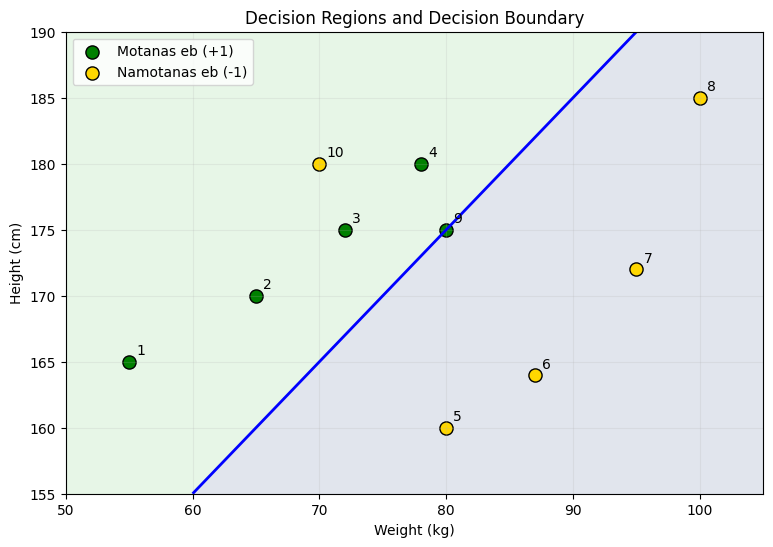

In [9]:
def plot_decision_regions(X, y, w0, w1, w2):
    x_min, x_max = 50, 105
    y_min, y_max = 155, 190
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    zz = w0 + w1 * xx + w2 * yy

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, (zz >= 0).astype(int),
                 levels=[-0.5, 0.5, 1.5], alpha=0.15)
    plt.contour(xx, yy, zz, levels=[0], colors="blue", linewidths=2)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="green", s=90, label="Motanas eb (+1)", edgecolors="black")
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color="gold", s=90, label="Namotanas eb (-1)", edgecolors="black")
    for i, (weight, height) in enumerate(X, start=1):
        plt.annotate(str(i), (weight, height), xytext=(5, 5), textcoords="offset points")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title("Decision Regions and Decision Boundary")
    plt.xlabel("Weight (kg)")
    plt.ylabel("Height (cm)")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.show()

plot_decision_regions(X, y, best["w0"], best["w1"], best["w2"])

: پاسخ پرسش پایانی

اگر داده‌های آموزش کاملاً خط‌جدایی‌پذیر نباشند، دسته‌بندی خطی هنوز می‌تواند منطقی باشد؛ چون ساده، قابل‌فهم و قابل‌تفسیر است. اما یک خط مستقیم نمی‌تواند هر الگوی پیچیده‌ای را جدا کند و ممکن است مقداری خطا باقی بماند. اگر این خطا برای مسئله زیاد باشد، می‌توان ویژگی‌های بیشتری اضافه کرد یا سراغ مرز تصمیم غیرخطی رفت. البته پیچیده‌تر کردن مدل همیشه بهتر نیست، چون ممکن است مدل به داده‌های آموزش بیش از حد وابسته شود. در نهایت باید خطای آموزش و آزمون را با هم بررسی کنیم.